# Comparison of Three Machine Learning Models Using Health Measurements Data

## 1. Introduction

Machine learning is a set of methods that learn patterns from example data and use those patterns to make predictions on new observations. In this experiment, three supervised regression algorithms will use **Age**, **Height_cm**, and **Weight_kg** to estimate **Pulse_rate_bpm**.

The purpose is to build, evaluate, and compare Linear Regression, Random Forest Regression, and K-Nearest Neighbors (KNN) Regression on the same training and test observations. Linear Regression provides a simple linear baseline, Random Forest can represent nonlinear relationships and interactions, and KNN predicts from nearby examples and is sensitive to feature scale. Comparing them illustrates how different modeling assumptions affect predictions on a small dataset.

The workbook is expected to contain 100 observations and four variables: **Age**, **Height_cm**, **Weight_kg**, and **Pulse_rate_bpm**. The objectives are to inspect and clean the data without changing the source workbook, explore its distributions and relationships, fit the three models, calculate test-set regression metrics, compare actual and predicted values, and draw conclusions only from the observed results.

**Important limitation:** The supplied observations are synthetic, not actual patient measurements. All results are for educational purposes and are not medically valid predictions or advice.

## 2. Import libraries

This notebook uses pandas and NumPy for data handling, Matplotlib and Seaborn for plots, and scikit-learn for splitting, preprocessing, models, and metrics. Excel reading also requires an engine such as `openpyxl`. The next cell checks these dependencies and raises an actionable error if one is missing. No packages are installed automatically and the environment is not modified.

If a dependency is missing, activate the project's `.venv` and install the missing package there, for example: `python -m pip install pandas numpy matplotlib seaborn scikit-learn openpyxl`. In a notebook, the corresponding environment-safe command is `%pip install pandas numpy matplotlib seaborn scikit-learn openpyxl`; restart the kernel after installation.

In [1]:
from importlib.util import find_spec

required_packages = {
    "pandas": "pandas",
    "numpy": "numpy",
    "matplotlib": "matplotlib",
    "seaborn": "seaborn",
    "sklearn": "scikit-learn",
    "openpyxl": "openpyxl",
}
missing_packages = [
    package for module, package in required_packages.items()
    if find_spec(module) is None
]
if missing_packages:
    raise ImportError(
        "Missing dependencies: " + ", ".join(missing_packages) +
        ". Install them in this notebook's kernel environment with: %pip install " +
        " ".join(missing_packages)
    )

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.precision", 3)
print("All required packages are available.")

All required packages are available.


## 3. Load the dataset

The workbook is read from the same folder as this notebook, so the source path does not depend on the current working directory. The original Excel file is only read; all subsequent cleaning is performed in memory.

In [2]:
from pathlib import Path

NOTEBOOK_DIR = Path.cwd()
DATA_PATH = NOTEBOOK_DIR / "health_measurements_100_observations.xlsx"
if not DATA_PATH.is_file():
    raise FileNotFoundError(
        f"Dataset not found at {DATA_PATH}. Place the notebook beside "
        "health_measurements_100_observations.xlsx, or update DATA_PATH."
    )

df_raw = pd.read_excel(DATA_PATH)
print(f"Loaded workbook: {DATA_PATH.resolve()}")
print("\nFirst five rows:")
display(df_raw.head())
print("\nLast five rows:")
display(df_raw.tail())
print(f"\nDataset dimensions: {df_raw.shape[0]} rows x {df_raw.shape[1]} columns")
print("Column names:", df_raw.columns.tolist())
print("\nData types:")
display(df_raw.dtypes.to_frame("data_type"))
print("\nDescriptive statistics:")
display(df_raw.describe(include="all").T)

expected_columns = ["Age", "Height_cm", "Weight_kg", "Pulse_rate_bpm"]
print(
    f"\nExpected 100 observations and four variables: "
    f"{df_raw.shape == (100, 4)} (observed shape: {df_raw.shape})."
)
if list(df_raw.columns) != expected_columns:
    raise ValueError(
        f"Expected columns in this order: {expected_columns}; "
        f"found: {df_raw.columns.tolist()}"
    )
if df_raw.shape != (100, 4):
    raise ValueError(
        f"Expected exactly 100 observations and 4 variables; found {df_raw.shape}. "
        "Check the workbook before continuing."
    )

Loaded workbook: C:\Users\David Dagbanja\Desktop\New folder\health_measurements_100_observations.xlsx

First five rows:


,Age,Height_cm,Weight_kg,Pulse_rate_bpm
0,60,168.6,70.9,67
1,32,146.3,78.4,88
2,39,153.2,76.2,55
3,49,172.6,70.8,89
4,53,170.9,93.2,75



Last five rows:


,Age,Height_cm,Weight_kg,Pulse_rate_bpm
95,46,171.4,72.9,89
96,22,159.2,59.0,97
97,39,167.7,78.7,78
98,64,160.7,58.1,77
99,65,172.8,71.6,75



Dataset dimensions: 100 rows x 4 columns
Column names: ['Age', 'Height_cm', 'Weight_kg', 'Pulse_rate_bpm']

Data types:


,data_type
Age,int64
Height_cm,float64
Weight_kg,float64
Pulse_rate_bpm,int64



Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
Age,100.0,44.930,15.191,18.0,32.000,44.0,60.00,70.0
Height_cm,100.0,168.399,8.755,146.3,162.750,168.6,174.40,186.5
Weight_kg,100.0,72.922,12.712,42.0,64.175,71.5,81.05,109.3
Pulse_rate_bpm,100.0,78.030,13.727,55.0,65.000,77.5,89.25,100.0



Expected 100 observations and four variables: True (observed shape: (100, 4)).


## 4. Data cleaning

First inspect nulls, duplicate rows, types, and values that cannot be interpreted as numeric. Numeric conversion is explicit and non-numeric entries become missing so that they can be counted and handled rather than silently used as text. For these measurement fields, negative ages and non-positive heights, weights, or pulse rates are invalid. Rows with missing or invalid model inputs/targets are excluded from the analysis; exact duplicate rows are also removed. No imputation or changes to the original workbook are made. The cleaning report below shows every affected-row count.

In [3]:
print("Missing values by column before cleaning:")
display(df_raw.isna().sum().to_frame("missing_count"))
duplicate_count = int(df_raw.duplicated().sum())
print(f"Exact duplicate rows before cleaning: {duplicate_count}")
print("Original data types:")
display(df_raw.dtypes.to_frame("data_type"))

df_clean = df_raw.copy()
numeric_columns = ["Age", "Height_cm", "Weight_kg", "Pulse_rate_bpm"]
for column in numeric_columns:
    df_clean[column] = pd.to_numeric(df_clean[column], errors="coerce")

non_numeric_or_missing = df_clean[numeric_columns].isna().any(axis=1)
non_finite = ~np.isfinite(df_clean[numeric_columns].to_numpy(dtype=float)).all(axis=1)
invalid_ranges = (
    (df_clean["Age"] < 0) |
    (df_clean["Height_cm"] <= 0) |
    (df_clean["Weight_kg"] <= 0) |
    (df_clean["Pulse_rate_bpm"] <= 0)
)
invalid_rows = non_numeric_or_missing | non_finite | invalid_ranges
invalid_row_count = int(invalid_rows.sum())
df_clean = df_clean.loc[~invalid_rows].drop_duplicates().reset_index(drop=True)

cleaning_report = pd.Series(
    {
        "rows in original workbook": len(df_raw),
        "rows with missing/non-numeric values": int(non_numeric_or_missing.sum()),
        "rows with non-finite values": int(non_finite.sum()),
        "rows with invalid measurement ranges": int(invalid_ranges.sum()),
        "rows removed for invalid/missing values": invalid_row_count,
        "duplicate rows removed": duplicate_count,
        "rows retained for analysis": len(df_clean),
    },
    name="count",
).to_frame()
display(cleaning_report)
print("Cleaned data types:")
display(df_clean.dtypes.to_frame("data_type"))
print("Missing values after cleaning:")
display(df_clean.isna().sum().to_frame("missing_count"))
if len(df_clean) < 10:
    raise ValueError(
        f"Only {len(df_clean)} valid unique observations remain; "
        "there are too few for the requested train/test experiment."
    )
print(
    f"\nCleaning complete in memory. {len(df_clean)} valid unique rows remain; "
    "the source workbook has not been modified."
)

Missing values by column before cleaning:


,missing_count
Age,0
Height_cm,0
Weight_kg,0
Pulse_rate_bpm,0


Exact duplicate rows before cleaning: 0
Original data types:


,data_type
Age,int64
Height_cm,float64
Weight_kg,float64
Pulse_rate_bpm,int64


,count
rows in original workbook,100
rows with missing/non-numeric values,0
rows with non-finite values,0
rows with invalid measurement ranges,0
rows removed for invalid/missing values,0
duplicate rows removed,0
rows retained for analysis,100


Cleaned data types:


,data_type
Age,int64
Height_cm,float64
Weight_kg,float64
Pulse_rate_bpm,int64


Missing values after cleaning:


,missing_count
Age,0
Height_cm,0
Weight_kg,0
Pulse_rate_bpm,0



Cleaning complete in memory. 100 valid unique rows remain; the source workbook has not been modified.


## 5. Exploratory data analysis

The distribution plots show each variable's observed values, while the correlation heatmap summarizes pairwise linear association (not causation). Scatter plots help inspect possible relationships between every pair of measurements. The written observations are computed from the cleaned data and the plots; they do not imply clinical meaning.

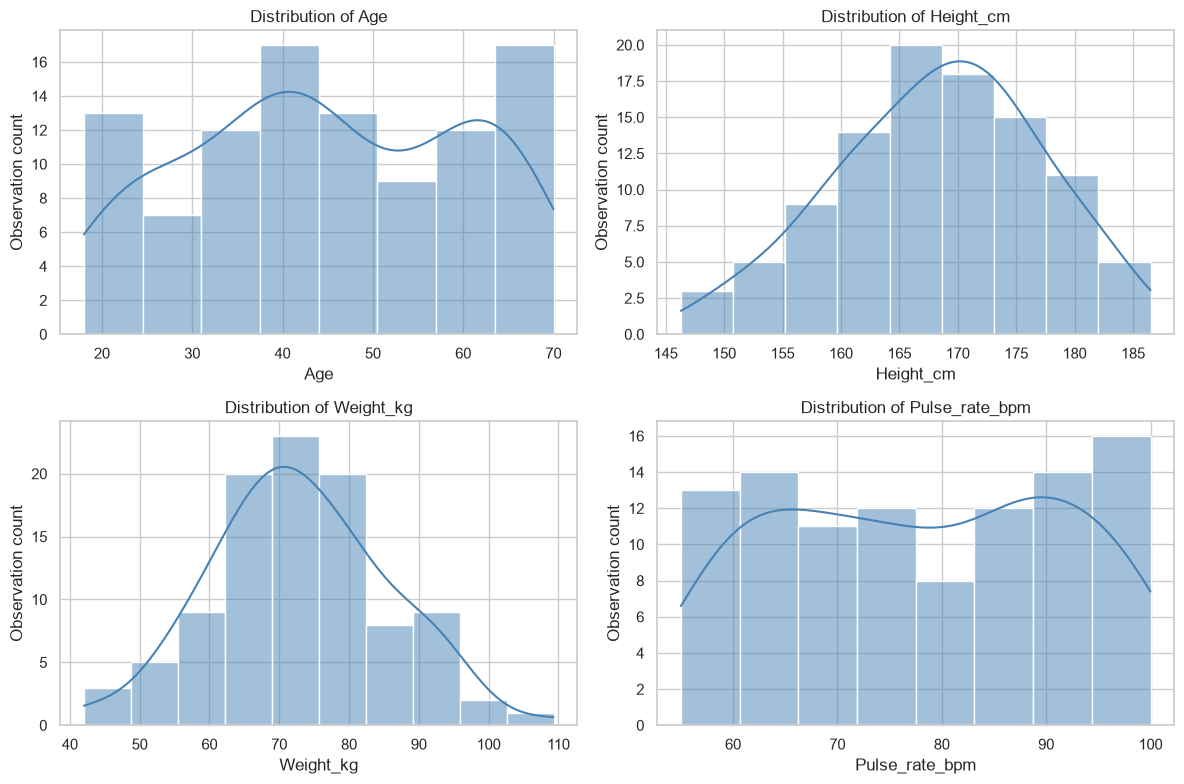

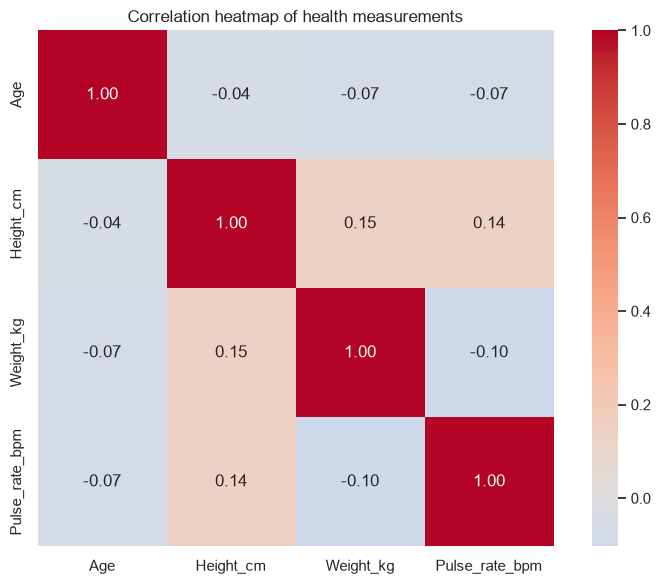

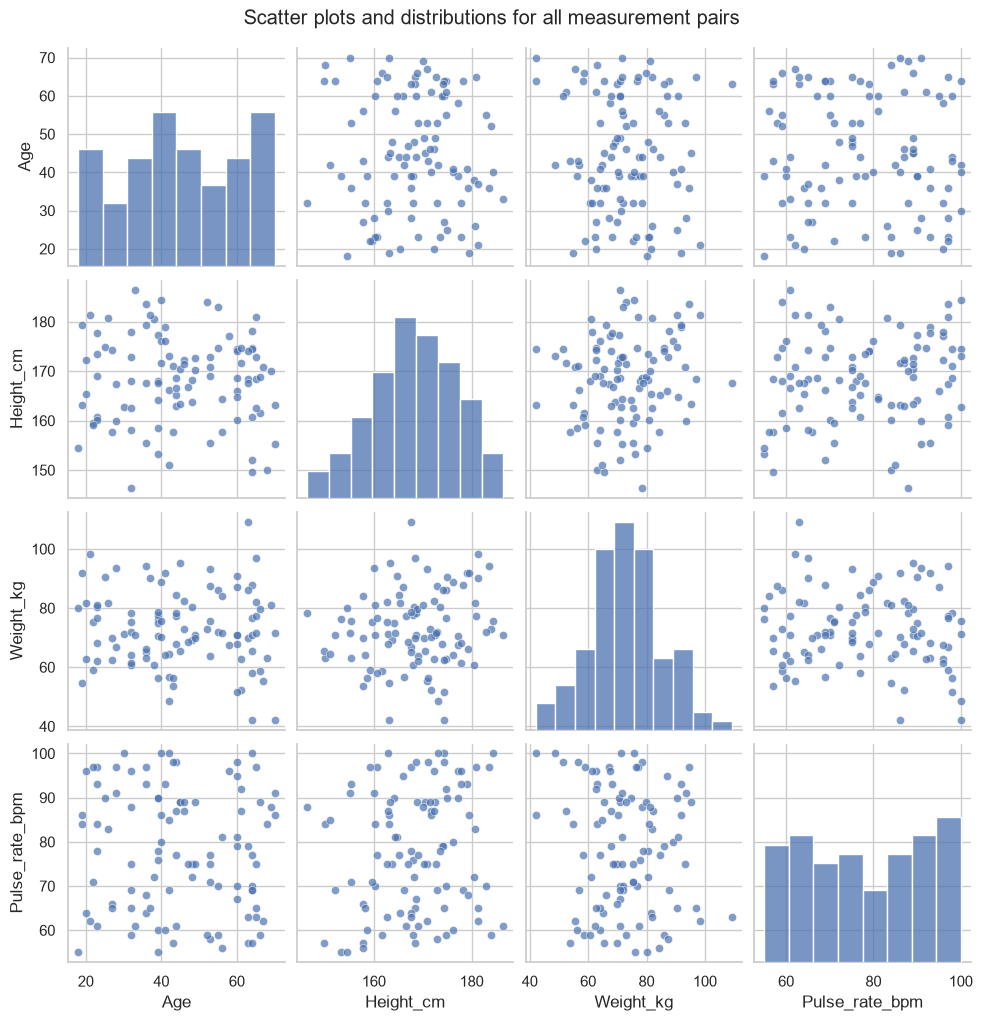

Data-driven observations:
- The observed pulse-rate range is 55.0 to 100.0 bpm.
- Among the three candidate inputs, Height_cm has the largest absolute sample correlation with pulse rate (r = 0.14).
- Histograms and pairwise plots display the observed sample distributions and relationships; with a small synthetic sample, patterns may be unstable and should not be interpreted as causal or medical evidence.


In [4]:
measurement_columns = ["Age", "Height_cm", "Weight_kg", "Pulse_rate_bpm"]
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, column in zip(axes.flat, measurement_columns):
    sns.histplot(data=df_clean, x=column, kde=True, ax=ax, color="steelblue")
    ax.set_title(f"Distribution of {column}")
    ax.set_ylabel("Observation count")
fig.tight_layout()
plt.show()

plt.figure(figsize=(8, 6))
correlation = df_clean[measurement_columns].corr(numeric_only=True)
sns.heatmap(correlation, annot=True, cmap="coolwarm", center=0, fmt=".2f", square=True)
plt.title("Correlation heatmap of health measurements")
plt.tight_layout()
plt.show()

pair_plot = sns.pairplot(
    df_clean[measurement_columns],
    diag_kind="hist",
    plot_kws={"alpha": 0.7, "s": 35},
)
pair_plot.fig.suptitle("Scatter plots and distributions for all measurement pairs", y=1.02)
plt.show()

target_correlations = correlation["Pulse_rate_bpm"].drop("Pulse_rate_bpm").sort_values(
    key=lambda values: values.abs(), ascending=False
)
strongest_feature = target_correlations.index[0]
strongest_value = float(target_correlations.iloc[0])
print("Data-driven observations:")
print(
    f"- The observed pulse-rate range is {df_clean['Pulse_rate_bpm'].min():.1f} to "
    f"{df_clean['Pulse_rate_bpm'].max():.1f} bpm."
)
print(
    f"- Among the three candidate inputs, {strongest_feature} has the largest "
    f"absolute sample correlation with pulse rate (r = {strongest_value:.2f})."
)
print(
    "- Histograms and pairwise plots display the observed sample distributions and "
    "relationships; with a small synthetic sample, patterns may be unstable and "
    "should not be interpreted as causal or medical evidence."
)

## 6. Define features and target

The models will attempt to predict pulse rate using age, height, and weight. The feature matrix `X` contains the three specified inputs, and `y` contains the target `Pulse_rate_bpm`.

In [5]:
df = df_clean
X = df[["Age", "Height_cm", "Weight_kg"]]
y = df["Pulse_rate_bpm"]
print(f"Feature matrix shape: {X.shape}")
print(f"Target vector shape: {y.shape}")
display(X.head())

Feature matrix shape: (100, 3)
Target vector shape: (100,)


,Age,Height_cm,Weight_kg
0,60,168.6,70.9
1,32,146.3,78.4
2,39,153.2,76.2
3,49,172.6,70.8
4,53,170.9,93.2


## 7. Split the dataset

A fixed 80% training / 20% testing split is made with `random_state=42`. The same rows are used for all three algorithms so the comparison is fair. If cleaning removed rows, these percentages apply to the valid, unique observations that remain.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)
print(f"Training observations: {len(X_train)} ({len(X_train) / len(X):.0%})")
print(f"Testing observations: {len(X_test)} ({len(X_test) / len(X):.0%})")
assert len(X_train) + len(X_test) == len(X)
assert X_train.index.intersection(X_test.index).empty
assert y_train.index.equals(X_train.index) and y_test.index.equals(X_test.index)

Training observations: 80 (80%)
Testing observations: 20 (20%)


## 8. Build the three models

Linear Regression and Random Forest use the same unscaled input features. KNN uses a `Pipeline` containing `StandardScaler` followed by KNN with `n_neighbors=5`. KNN depends on distances: a feature measured on a numerically larger scale can dominate those distances. Standardization gives each feature a comparable scale. Keeping the scaler inside the pipeline ensures its means and standard deviations are fitted only on the training data, avoiding test-data leakage.

In [7]:
models = {
    "Linear Regression": LinearRegression(),
    "Random Forest Regression": RandomForestRegressor(random_state=42),
    "K-Nearest Neighbors Regression": Pipeline(
        steps=[
            ("scaler", StandardScaler()),
            ("knn", KNeighborsRegressor(n_neighbors=5)),
        ]
    ),
}

predictions = {}
for model_name, model in models.items():
    model.fit(X_train, y_train)
    predictions[model_name] = model.predict(X_test)
    print(f"{model_name}: trained; generated {len(predictions[model_name])} test predictions.")

assert all(len(prediction) == len(y_test) for prediction in predictions.values())

Linear Regression: trained; generated 20 test predictions.
Random Forest Regression: trained; generated 20 test predictions.


K-Nearest Neighbors Regression: trained; generated 20 test predictions.


## 9. Evaluate the models

Each score is calculated from the same actual test values and that model's predictions:

- **MAE** is the mean absolute prediction error, in pulse-rate units. Lower generally means smaller errors.
- **MSE** is the mean squared error; squaring gives larger errors more influence. Its unit is squared pulse-rate units. Lower generally means smaller errors.
- **RMSE** is the square root of MSE and is in pulse-rate units, making it easier to compare with the target. Lower generally means smaller errors.
- **R²** compares squared prediction error with the baseline of predicting the test-set mean. Higher generally indicates a better fit relative to that baseline. R² can be negative on unseen data when predictions are worse than the mean baseline.

No performance values are pre-entered; the following table is computed from the fitted models.

In [8]:
metric_rows = []
for model_name, y_pred in predictions.items():
    mse = mean_squared_error(y_test, y_pred)
    metric_rows.append(
        {
            "Model name": model_name,
            "MAE": mean_absolute_error(y_test, y_pred),
            "MSE": mse,
            "RMSE": np.sqrt(mse),
            "R²": r2_score(y_test, y_pred),
        }
    )

comparison = pd.DataFrame(metric_rows).sort_values("RMSE").reset_index(drop=True)
display(comparison.round(3))

,Model name,MAE,MSE,RMSE,R²
0,Linear Regression,8.617,114.518,10.701,0.031
1,Random Forest Regression,8.648,116.867,10.810,0.012
2,K-Nearest Neighbors Regression,10.490,151.338,12.302,-0.280


## 10. Compare model performance

The following charts compare MAE, RMSE, and R² as calculated above. RMSE is the primary selection metric; the model with the smallest observed test RMSE is identified after fitting. MAE and R² provide supporting evidence. This selection describes only this one fixed split, not guaranteed future performance.

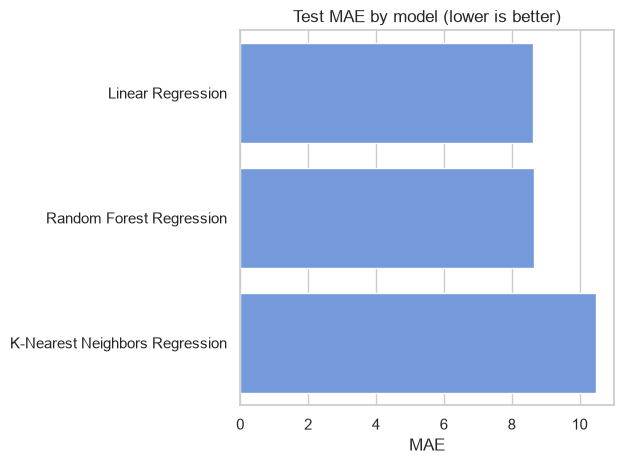

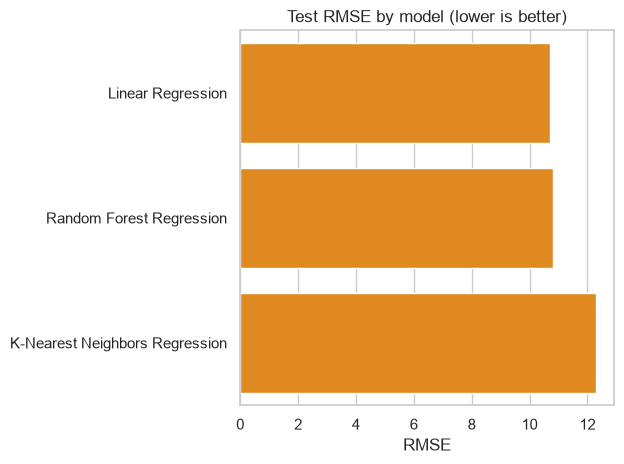

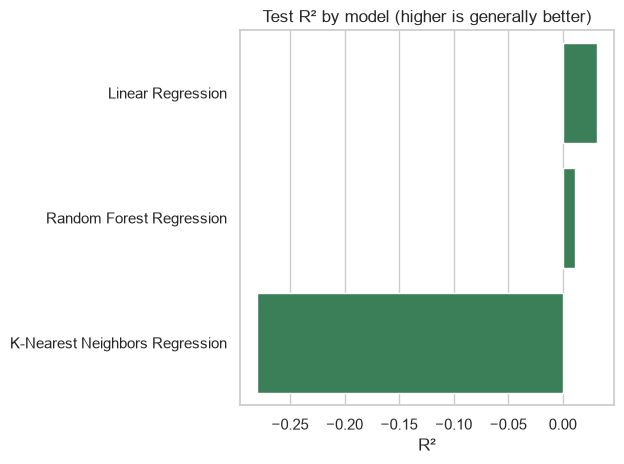

Best model by test RMSE: Linear Regression (RMSE=10.701, MAE=8.617, R²=0.031).
The other models and all scores are shown in the comparison table above.


In [9]:
best_model_name = comparison.loc[comparison["RMSE"].idxmin(), "Model name"]
best_rmse = float(comparison.loc[comparison["Model name"] == best_model_name, "RMSE"].iloc[0])
best_mae = float(comparison.loc[comparison["Model name"] == best_model_name, "MAE"].iloc[0])
best_r2 = float(comparison.loc[comparison["Model name"] == best_model_name, "R²"].iloc[0])

for metric, title, color in [
    ("MAE", "Test MAE by model (lower is better)", "cornflowerblue"),
    ("RMSE", "Test RMSE by model (lower is better)", "darkorange"),
    ("R²", "Test R² by model (higher is generally better)", "seagreen"),
]:
    ordered = comparison.sort_values(metric, ascending=(metric != "R²"))
    ax = sns.barplot(data=ordered, x=metric, y="Model name", color=color)
    ax.set_title(title)
    ax.set_xlabel(metric)
    ax.set_ylabel("")
    plt.tight_layout()
    plt.show()

print(
    f"Best model by test RMSE: {best_model_name} "
    f"(RMSE={best_rmse:.3f}, MAE={best_mae:.3f}, R²={best_r2:.3f})."
)
print("The other models and all scores are shown in the comparison table above.")

## 11. Actual versus predicted values

The table aligns each held-out observation's actual pulse rate with predictions from all three models. Each scatter plot compares one model's predictions with actual values; the diagonal reference line represents perfect predictions.

,Actual_Pulse_rate_bpm,Linear Regression_prediction,Random Forest Regression_prediction,K-Nearest Neighbors Regression_prediction
0,67,77.55,79.40,77.4
4,75,75.39,72.54,71.2
10,76,77.82,75.71,82.4
12,87,80.87,92.72,85.8
18,64,77.83,81.92,80.4
22,80,78.13,79.96,80.0
30,77,75.79,79.16,82.6
31,100,78.04,85.07,80.0
33,64,79.70,77.66,83.6
39,96,82.22,78.89,75.0


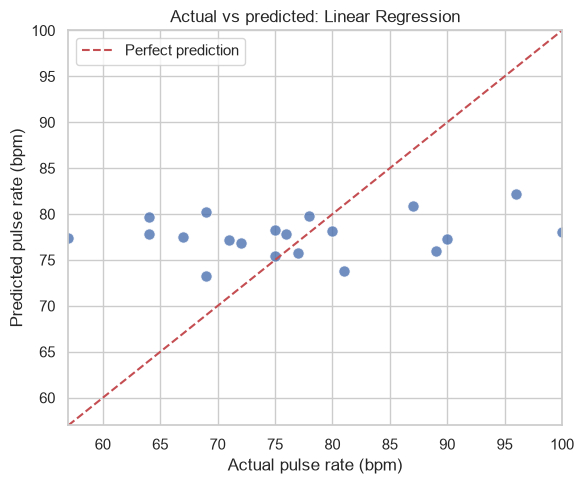

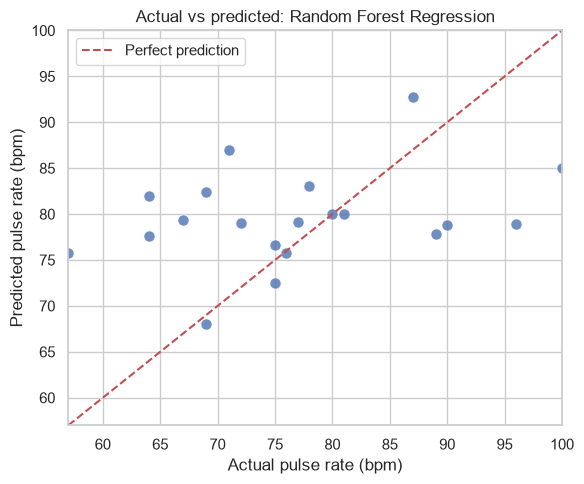

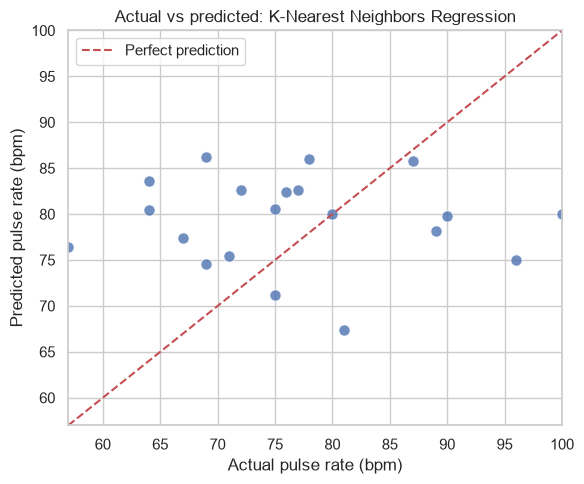

In [10]:
actual_vs_predicted = pd.DataFrame(
    {
        "Actual_Pulse_rate_bpm": y_test.to_numpy(),
        **{f"{name}_prediction": pred for name, pred in predictions.items()},
    },
    index=y_test.index,
).sort_index()
display(actual_vs_predicted.round(2))

lower_bound = min(float(y_test.min()), *(float(np.min(p)) for p in predictions.values()))
upper_bound = max(float(y_test.max()), *(float(np.max(p)) for p in predictions.values()))
for model_name, y_pred in predictions.items():
    plt.figure(figsize=(6, 5))
    sns.scatterplot(x=y_test.to_numpy(), y=y_pred, s=65, alpha=0.8)
    plt.plot([lower_bound, upper_bound], [lower_bound, upper_bound], "r--", label="Perfect prediction")
    plt.xlim(lower_bound, upper_bound)
    plt.ylim(lower_bound, upper_bound)
    plt.xlabel("Actual pulse rate (bpm)")
    plt.ylabel("Predicted pulse rate (bpm)")
    plt.title(f"Actual vs predicted: {model_name}")
    plt.legend()
    plt.tight_layout()
    plt.show()

## 12. Discussion and conclusion

The discussion below is generated from the test-set metrics calculated in this run. The RMSE-ranked model is called the best only for this particular split. Error size is reported in the target's units and described numerically rather than labeled medically acceptable or unacceptable.

In [11]:
best_row = comparison.loc[comparison["Model name"] == best_model_name].iloc[0]
test_target_mean = float(y_test.mean())
best_rmse_relative = best_rmse / abs(test_target_mean) if test_target_mean != 0 else np.nan
worst_model_name = comparison.loc[comparison["RMSE"].idxmax(), "Model name"]
rmse_spread = float(comparison["RMSE"].max() - comparison["RMSE"].min())
print("Conclusion based on this test split:")
print(
    f"- {best_model_name} had the lowest test RMSE ({best_rmse:.3f} bpm), "
    f"so it performed best by the primary metric on this split. Its MAE was "
    f"{best_mae:.3f} bpm and its R² was {best_r2:.3f}."
)
print(
    f"- Across the three models, test RMSE ranged from {comparison['RMSE'].min():.3f} "
    f"to {comparison['RMSE'].max():.3f} bpm (a spread of {rmse_spread:.3f} bpm). "
    f"For the RMSE-leading model, the typical squared-error scale expressed as RMSE "
    f"is {best_rmse_relative:.1%} of the test-set mean pulse rate. This is a descriptive "
    "comparison only, not a medical threshold."
)
print(
    "- Linear Regression fits a linear relationship; Random Forest combines decision "
    "trees and can capture nonlinear patterns; KNN averages outcomes among nearby "
    "training examples and relies on scaled distances. Their observed score differences "
    "are summarized in the comparison table."
)
if best_r2 < 0:
    print(
        "- The RMSE-leading model still has negative test R², meaning it is worse than "
        "the test-set-mean baseline under R² despite ranking first among these models."
    )
print(
    "- The sample contains only 100 synthetic observations (and may contain fewer after "
    "cleaning). With few examples, a flexible model such as a forest can overfit the "
    "training data; training fit is not a substitute for validation on new data."
)
print(
    "- A single random 80/20 split leaves a small test set, so a few observations can "
    "materially change the metrics and model ranking. Repeated cross-validation and a "
    "larger, representative dataset would give a more stable educational assessment."
)
print(
    "- These are synthetic measurements and the models have not been clinically "
    "validated. Predictions must not be used for diagnosis, treatment, or other health decisions."
)

Conclusion based on this test split:
- Linear Regression had the lowest test RMSE (10.701 bpm), so it performed best by the primary metric on this split. Its MAE was 8.617 bpm and its R² was 0.031.
- Across the three models, test RMSE ranged from 10.701 to 12.302 bpm (a spread of 1.601 bpm). For the RMSE-leading model, the typical squared-error scale expressed as RMSE is 13.9% of the test-set mean pulse rate. This is a descriptive comparison only, not a medical threshold.
- Linear Regression fits a linear relationship; Random Forest combines decision trees and can capture nonlinear patterns; KNN averages outcomes among nearby training examples and relies on scaled distances. Their observed score differences are summarized in the comparison table.
- The sample contains only 100 synthetic observations (and may contain fewer after cleaning). With few examples, a flexible model such as a forest can overfit the training data; training fit is not a substitute for validation on new data.
- A 

## 13. Final verification

Run this last cell after executing the notebook from top to bottom. It verifies the source path, expected source dimensions, common held-out split, predictions from all models, all four computed metrics, and the comparison/actual-versus-predicted tables. The charts above are generated in Sections 5, 10, and 11.

In [12]:
assert DATA_PATH.is_file(), f"Excel file path is invalid: {DATA_PATH}"
assert df_raw.shape == (100, 4), f"Unexpected raw dataset dimensions: {df_raw.shape}"
assert len(X_train) + len(X_test) == len(df_clean)
assert len(models) == 3 and len(predictions) == 3
assert set(models) == set(predictions)
assert all(len(values) == len(y_test) for values in predictions.values())
required_metrics = {"MAE", "MSE", "RMSE", "R²"}
assert required_metrics.issubset(comparison.columns)
assert len(comparison) == 3 and np.isfinite(comparison[list(required_metrics)].to_numpy()).all()
assert len(actual_vs_predicted) == len(y_test)
assert actual_vs_predicted.shape[1] == 4
print("FINAL VERIFICATION PASSED")
print(f"Dataset: {DATA_PATH.resolve()} (original workbook unchanged)")
print(f"Original dimensions: {df_raw.shape}; cleaned observations: {len(df_clean)}")
print(f"Shared split: {len(X_train)} train / {len(X_test)} test observations")
print(f"Models trained and predictions generated: {', '.join(models)}")
print("All four metrics calculated from test values; comparison and prediction tables generated.")
print("Distribution, correlation, model-comparison, and actual-vs-predicted plots generated above.")

FINAL VERIFICATION PASSED
Dataset: C:\Users\David Dagbanja\Desktop\New folder\health_measurements_100_observations.xlsx (original workbook unchanged)
Original dimensions: (100, 4); cleaned observations: 100
Shared split: 80 train / 20 test observations
Models trained and predictions generated: Linear Regression, Random Forest Regression, K-Nearest Neighbors Regression
All four metrics calculated from test values; comparison and prediction tables generated.
Distribution, correlation, model-comparison, and actual-vs-predicted plots generated above.
